In [2]:
import os
if not os.path.exists('IRkernel_installed'):
  # Install R kernel and dependencies
  !R -e 'install.packages(c("repr", "IRdisplay", "evaluate", "crayon", "pbdZMQ", "devtools", "uuid", "digest", "remotes"))'
  !R -e 'remotes::install_github("IRkernel/IRkernel")'
  !R -e 'IRkernel::installspec(user = FALSE)'
  !touch IRkernel_installed


After running the cell above, you will need to restart the runtime and then change the notebook settings:

1. Go to `Runtime` -> `Restart runtime`.
2. Go to `Runtime` -> `Change runtime type`.
3. In the dropdown, select `R` and click `Save`.

Once done, you can start writing R code directly in your cells.

In [1]:
install.packages(c("naniar", "skimr"))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘gridExtra’, ‘plyr’, ‘norm’, ‘visdat’, ‘viridis’, ‘UpSetR’




In [9]:
# This cell was for installing 'pdftools' when in Python mode.
# With the notebook now in R mode, packages should be installed directly using install.packages().
# This cell is now commented out as it's no longer necessary.

Now that you have the `pdftools` package installed, you can use it to read the content of your PDF file. Remember to switch to an R code cell to use R syntax directly.

Here's how to read the PDF content:

In [10]:
# This cell was for loading 'pdftools' and reading PDF content when in Python mode.
# With the notebook now in R mode, you can use R syntax directly.
# This cell is now commented out as its original purpose with `!R -e` is no longer applicable.

In [2]:
library(naniar)
library(skimr)


Attaching package: ‘skimr’


The following object is masked from ‘package:naniar’:

    n_complete




In [ ]:
# Assignment 2 – R Programming Lab

## Lab 3: Control Flow for Data Cleaning

### Aim
To clean healthcare data using R functions, if-else conditions,
error handling, loops, and vectorized operations.

In [3]:
# Install packages if required
install.packages("dplyr")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [4]:
library(dplyr)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [12]:
# Install/read required package
install.packages("readr")
library(readr)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [16]:
# Create a sample Heart Disease dataset

set.seed(123)

heart_data <- data.frame(
  age = sample(30:75, 1000, replace = TRUE),

  trestbps = sample(
    90:200,
    1000,
    replace = TRUE
  ),

  chol = sample(
    150:400,
    1000,
    replace = TRUE
  ),

  maxhr = sample(
    100:200,
    1000,
    replace = TRUE
  )
)

# Display first 6 rows
head(heart_data)

,age,trestbps,chol,maxhr
,<int>,<int>,<int>,<int>
1,60,124,224,109
2,44,119,279,136
3,43,123,277,117
4,32,158,337,177
5,71,158,296,121
6,72,160,389,192


In [17]:
# Check structure
str(heart_data)

# Check dimensions
dim(heart_data)

# Summary statistics
summary(heart_data)

'data.frame':	1000 obs. of  4 variables:
 $ age     : int  60 44 43 32 71 72 66 43 54 55 ...
 $ trestbps: int  124 119 123 158 158 160 91 169 193 112 ...
 $ chol    : int  224 279 277 337 296 389 343 270 190 364 ...
 $ maxhr   : int  109 136 117 177 121 192 118 182 149 137 ...


[1] 1000    4

      age          trestbps          chol           maxhr      
 Min.   :30.0   Min.   : 90.0   Min.   :150.0   Min.   :100.0  
 1st Qu.:41.0   1st Qu.:117.0   1st Qu.:209.0   1st Qu.:123.0  
 Median :53.0   Median :145.0   Median :268.5   Median :147.0  
 Mean   :52.6   Mean   :145.4   Mean   :272.0   Mean   :148.7  
 3rd Qu.:64.0   3rd Qu.:172.0   3rd Qu.:336.0   3rd Qu.:174.0  
 Max.   :75.0   Max.   :200.0   Max.   :400.0   Max.   :200.0  

In [19]:
# Introduce negative BP values
heart_data$trestbps[c(5, 10, 15)] <- c(-20, -50, -10)

# Introduce missing BP values
heart_data$trestbps[c(20, 25, 30)] <- NA

# Introduce extreme BP values
heart_data$trestbps[c(35, 40, 45)] <- c(320, 350, 400)

In [20]:
# Display the modified observations
heart_data[c(5, 10, 15, 20, 25, 30, 35, 40, 45), ]

,age,trestbps,chol,maxhr
,<int>,<dbl>,<int>,<int>
5,71,-20,296,121
10,55,-50,364,137
15,38,-10,358,111
20,36,NA,291,173
25,43,NA,351,153
30,44,NA,280,178
35,38,320,179,135
40,36,350,324,178
45,63,400,260,162


In [21]:
# BP Cleaning Function

clean_bp <- function(bp) {

  if (is.na(bp)) {
    return(NA)

  } else if (bp < 0) {
    return(NA)

  } else if (bp > 250) {
    return(250)

  } else {
    return(bp)
  }
}

In [22]:
# Test the BP cleaning function

clean_bp(-20)
clean_bp(320)
clean_bp(120)
clean_bp(NA)

[1] NA

[1] 250

[1] 120

[1] NA

In [23]:
# Apply cleaning function to all BP values

heart_data$trestbps_clean <- sapply(
  heart_data$trestbps,
  clean_bp
)

# Display original and cleaned BP
head(
  heart_data[, c("trestbps", "trestbps_clean")],
  20
)

,trestbps,trestbps_clean
,<dbl>,<dbl>
1,124,124
2,119,119
3,123,123
4,158,158
5,-20,NA
6,160,160
7,91,91
8,169,169
9,193,193


In [24]:
# Calculate mean BP safely using tryCatch()

mean_bp <- tryCatch({

  mean(heart_data$trestbps_clean, na.rm = TRUE)

}, warning = function(w) {

  message("Warning while calculating mean BP: ", w$message)
  NA

}, error = function(e) {

  message("Error while calculating mean BP: ", e$message)
  NA
})

mean_bp

[1] 145.8491

In [25]:
mean(heart_data$trestbps_clean)

[1] NA

In [26]:
mean(heart_data$trestbps_clean, na.rm = TRUE)

[1] 145.8491

In [ ]:
chol / trestbps

In [27]:
# Calculate cholesterol / BP ratio safely

calculate_ratio <- function(chol, bp) {

  tryCatch({

    if (is.na(chol) || is.na(bp)) {
      stop("Cholesterol or BP is missing.")
    }

    if (bp == 0) {
      stop("Cannot divide by zero.")
    }

    if (bp < 0) {
      stop("BP cannot be negative.")
    }

    ratio <- chol / bp

    return(ratio)

  }, error = function(e) {

    message("Invalid ratio: ", e$message)
    return(NA)
  })
}

In [28]:
# Valid values
calculate_ratio(200, 120)

[1] 1.666667

In [29]:
calculate_ratio(200, 0)

Invalid ratio: Cannot divide by zero.



[1] NA

In [30]:
calculate_ratio(200, NA)

Invalid ratio: Cholesterol or BP is missing.



[1] NA

In [31]:
calculate_ratio(200, -50)

Invalid ratio: BP cannot be negative.



[1] NA

In [32]:
# Calculate cholesterol / BP ratio for all patients

heart_data$chol_bp_ratio <- mapply(
  calculate_ratio,
  heart_data$chol,
  heart_data$trestbps_clean
)

# View results
head(
  heart_data[, c("chol", "trestbps_clean", "chol_bp_ratio")],
  10
)

Invalid ratio: Cholesterol or BP is missing.

Invalid ratio: Cholesterol or BP is missing.

Invalid ratio: Cholesterol or BP is missing.

Invalid ratio: Cholesterol or BP is missing.

Invalid ratio: Cholesterol or BP is missing.

Invalid ratio: Cholesterol or BP is missing.



,chol,trestbps_clean,chol_bp_ratio
,<int>,<dbl>,<dbl>
1,224,124,1.806452
2,279,119,2.344538
3,277,123,2.252033
4,337,158,2.132911
5,296,NA,NA
6,389,160,2.431250
7,343,91,3.769231
8,270,169,1.597633
9,190,193,0.984456


In [33]:
# Loop-based BP cleaning

loop_clean_bp <- function(bp) {

  result <- bp

  for (i in 1:length(bp)) {

    if (is.na(bp[i])) {
      result[i] <- NA

    } else if (bp[i] < 0) {
      result[i] <- NA

    } else if (bp[i] > 250) {
      result[i] <- 250

    } else {
      result[i] <- bp[i]
    }
  }

  return(result)
}

In [34]:
loop_clean_bp(heart_data$trestbps)[1:10]

[1] 124 119 123 158  NA 160  91 169 193  NA

In [35]:
# Vectorized BP cleaning

vectorized_clean_bp <- function(bp) {

  result <- bp

  result[bp < 0] <- NA
  result[bp > 250] <- 250

  return(result)
}

In [36]:
vectorized_clean_bp(heart_data$trestbps)[1:10]

[1] 124 119 123 158  NA 160  91 169 193  NA

In [37]:
# Compare loop and vectorized results

loop_result <- loop_clean_bp(heart_data$trestbps)

vectorized_result <- vectorized_clean_bp(heart_data$trestbps)

identical(loop_result, vectorized_result)

[1] TRUE

In [38]:
# Measure loop execution time

loop_time <- system.time({
  for (j in 1:100) {
    loop_result <- loop_clean_bp(heart_data$trestbps)
  }
})

loop_time

   user  system elapsed 
  0.035   0.000   0.034 

In [39]:
# Measure vectorized execution time

vectorized_time <- system.time({
  for (j in 1:100) {
    vectorized_result <- vectorized_clean_bp(heart_data$trestbps)
  }
})

vectorized_time

   user  system elapsed 
  0.005   0.000   0.005 

In [40]:
# Compare execution times

comparison <- data.frame(
  Method = c("For Loop", "Vectorized"),
  Time = c(
    loop_time["user.self"],
    vectorized_time["user.self"]
  )
)

comparison

Method,Time
<chr>,<dbl>
For Loop,0.035
Vectorized,0.005


In [41]:
# Count missing BP values

missing_bp <- sum(is.na(heart_data$trestbps_clean))

missing_bp

[1] 6

In [42]:
# Minimum BP

min_bp <- min(
  heart_data$trestbps_clean,
  na.rm = TRUE
)

# Maximum BP

max_bp <- max(
  heart_data$trestbps_clean,
  na.rm = TRUE
)

# Mean BP

mean_bp <- mean(
  heart_data$trestbps_clean,
  na.rm = TRUE
)

# Median BP

median_bp <- median(
  heart_data$trestbps_clean,
  na.rm = TRUE
)

min_bp
max_bp
mean_bp
median_bp

[1] 90

[1] 250

[1] 145.8491

[1] 146

In [43]:
# Check for negative BP values

negative_values <- sum(
  heart_data$trestbps_clean < 0,
  na.rm = TRUE
)

# Check for BP values greater than 250

above_250 <- sum(
  heart_data$trestbps_clean > 250,
  na.rm = TRUE
)

negative_values
above_250

[1] 0

[1] 0

In [44]:
# Export cleaned dataset

write.csv(
  heart_data,
  "cleaned_heart_data.csv",
  row.names = FALSE
)

In [ ]:
## LAB 4: Advanced Missing Data Handling

### Aim
To identify, analyze, and treat different forms of missing and
invalid data such as NA, NaN, NULL, blank strings, and impossible
numeric values using R.

In [45]:
install.packages(c("naniar", "skimr"))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [46]:
library(naniar)
library(skimr)

In [48]:
set.seed(123)

adult_data <- data.frame(

  age = sample(18:70, 1000, replace = TRUE),

  workclass = sample(
    c("Private", "Government", "Self-employed", "Student"),
    1000,
    replace = TRUE
  ),

  education = sample(
    c("School", "Bachelor", "Master", "PhD"),
    1000,
    replace = TRUE
  ),

  occupation = sample(
    c("Engineer", "Teacher", "Manager", "Clerk", "Analyst"),
    1000,
    replace = TRUE
  ),

  hours_per_week = sample(
    20:60,
    1000,
    replace = TRUE
  ),

  income = sample(
    c("<=50K", ">50K"),
    1000,
    replace = TRUE
  )
)

head(adult_data)

,age,workclass,education,occupation,hours_per_week,income
,<int>,<chr>,<chr>,<chr>,<int>,<chr>
1,48,Self-employed,Bachelor,Teacher,39,<=50K
2,32,Self-employed,School,Clerk,21,>50K
3,68,Private,PhD,Teacher,35,>50K
4,31,Student,PhD,Clerk,33,<=50K
5,20,Self-employed,School,Clerk,56,<=50K
6,59,Private,PhD,Teacher,51,>50K


In [49]:
str(adult_data)

'data.frame':	1000 obs. of  6 variables:
 $ age           : int  48 32 68 31 20 59 67 60 54 69 ...
 $ workclass     : chr  "Self-employed" "Self-employed" "Private" "Student" ...
 $ education     : chr  "Bachelor" "School" "PhD" "PhD" ...
 $ occupation    : chr  "Teacher" "Clerk" "Teacher" "Clerk" ...
 $ hours_per_week: int  39 21 35 33 56 51 60 43 48 40 ...
 $ income        : chr  "<=50K" ">50K" ">50K" "<=50K" ...


In [50]:
dim(adult_data)

[1] 1000    6

In [51]:
dim(adult_data)

[1] 1000    6

In [52]:
summary(adult_data)

      age            workclass        education        occupation  
 Min.   :18.00   Length   :1000   Length   :1000   Length   :1000  
 1st Qu.:30.00   N.unique :   4   N.unique :   4   N.unique :   5  
 Median :43.00   N.blank  :   0   N.blank  :   0   N.blank  :   0  
 Mean   :43.76   Min.nchar:   7   Min.nchar:   3   Min.nchar:   5  
 3rd Qu.:57.00   Max.nchar:  13   Max.nchar:   8   Max.nchar:   8  
 Max.   :70.00                                                     
 hours_per_week        income    
 Min.   :20.00   Length   :1000  
 1st Qu.:30.00   N.unique :   2  
 Median :40.00   N.blank  :   0  
 Mean   :39.69   Min.nchar:   4  
 3rd Qu.:50.00   Max.nchar:   5  
 Max.   :60.00                   

In [54]:
# Introduce NA values
adult_data$age[c(5, 10, 15)] <- NA

# Introduce blank strings
adult_data$workclass[c(20, 25, 30)] <- ""

# Introduce NaN values
adult_data$hours_per_week[c(35, 40, 45)] <- NaN

# Introduce impossible age values
adult_data$age[c(50, 55, 60)] <- 999

In [53]:
adult_data[c(5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60), ]

,age,workclass,education,occupation,hours_per_week,income
,<int>,<chr>,<chr>,<chr>,<int>,<chr>
5,20,Self-employed,School,Clerk,56,<=50K
10,69,Private,School,Clerk,40,>50K
15,22,Private,School,Engineer,29,>50K
20,46,Private,Master,Engineer,60,<=50K
25,59,Student,Bachelor,Analyst,30,>50K
30,34,Student,Bachelor,Engineer,29,<=50K
35,32,Self-employed,Master,Manager,36,<=50K
40,26,Government,School,Analyst,30,<=50K
45,70,Student,PhD,Teacher,29,<=50K


In [55]:
# NA
x <- NA

# NaN
y <- NaN

# NULL
z <- NULL

# Blank string
w <- ""

is.na(x)
is.nan(y)
is.null(z)
w == ""

[1] TRUE

[1] TRUE

[1] TRUE

[1] TRUE

In [56]:
# Number of NA values in each column

colSums(is.na(adult_data))

age      workclass      education     occupation hours_per_week 
             3              0              0              0              3 
        income 
             0

In [57]:
# Number of NaN values in each column

sapply(adult_data, function(x) {
  sum(is.nan(x))
})

age      workclass      education     occupation hours_per_week 
             0              0              0              0              3 
        income 
             0

In [58]:
# Count blank strings in each column

sapply(adult_data, function(x) {
  if (is.character(x)) {
    sum(x == "", na.rm = TRUE)
  } else {
    0
  }
})

age      workclass      education     occupation hours_per_week 
             0              3              0              0              0 
        income 
             0

In [59]:
# Find impossible age values

sum(adult_data$age == 999, na.rm = TRUE)

[1] 3

In [60]:
# Variable-wise missing-value summary

miss_var_summary(adult_data)

variable,n_miss,pct_miss
<chr>,<int>,<num>
age,3,0.3
hours_per_week,3,0.3
workclass,0,0
education,0,0
occupation,0,0
income,0,0


In [61]:
# Total missing values before cleaning

total_missing_before <- sum(is.na(adult_data))

total_missing_before

[1] 6

In [62]:
# Percentage of missing values before cleaning

total_cells <- nrow(adult_data) * ncol(adult_data)

missing_percentage_before <-
  (total_missing_before / total_cells) * 100

missing_percentage_before

[1] 0.1

In [63]:
# Convert impossible age values to NA

adult_data$age[adult_data$age == 999] <- NA

In [64]:
sum(adult_data$age == 999, na.rm = TRUE)

[1] 0

In [65]:
# Replace blank workclass values

adult_data$workclass[
  adult_data$workclass == ""
] <- "Unknown"

In [66]:
sum(adult_data$workclass == "", na.rm = TRUE)

[1] 0

In [67]:
table(adult_data$workclass)


   Government       Private Self-employed       Student       Unknown 
          253           258           264           222             3 

In [68]:
# Custom median imputation function

median_impute <- function(x) {

  # Calculate median excluding missing values
  median_value <- median(x, na.rm = TRUE)

  # Replace missing values with median
  x[is.na(x)] <- median_value

  # Return cleaned vector
  return(x)
}

In [69]:
# Test median imputation

test_data <- c(10, 20, NA, 30, 40, NA)

test_data

[1] 10 20 NA 30 40 NA

In [70]:
median_impute(test_data)

[1] 10 20 25 30 40 25

In [71]:
# Impute missing age values using median

adult_data$age <- median_impute(adult_data$age)

In [72]:
sum(is.na(adult_data$age))

[1] 0

In [73]:
# Impute missing/NaN hours per week

adult_data$hours_per_week <- median_impute(
  adult_data$hours_per_week
)

In [74]:
# Check remaining NaN values

sapply(adult_data, function(x) {
  if (is.numeric(x)) {
    sum(is.nan(x))
  } else {
    0
  }
})

age      workclass      education     occupation hours_per_week 
             0              0              0              0              0 
        income 
             0

In [75]:
# Identify complete observations

complete_rows <- complete.cases(adult_data)

table(complete_rows)

complete_rows
TRUE 
1000 

In [76]:
# Number of incomplete observations

sum(!complete_rows)

[1] 0

In [77]:
# Missing values after cleaning

miss_var_summary(adult_data)

variable,n_miss,pct_miss
<chr>,<int>,<num>
age,0,0
workclass,0,0
education,0,0
occupation,0,0
hours_per_week,0,0
income,0,0


In [78]:
# Total missing values after cleaning

total_missing_after <- sum(is.na(adult_data))

total_missing_after

[1] 0

In [79]:
# Percentage missing after cleaning

missing_percentage_after <-
  (total_missing_after / total_cells) * 100

missing_percentage_after

[1] 0

In [80]:
# Create a copy for missingness visualization

adult_missing <- adult_data

# Introduce the same missing-data problems again for visualization
adult_missing$age[c(5, 10, 15)] <- NA
adult_missing$workclass[c(20, 25, 30)] <- ""
adult_missing$hours_per_week[c(35, 40, 45)] <- NaN
adult_missing$age[c(50, 55, 60)] <- 999

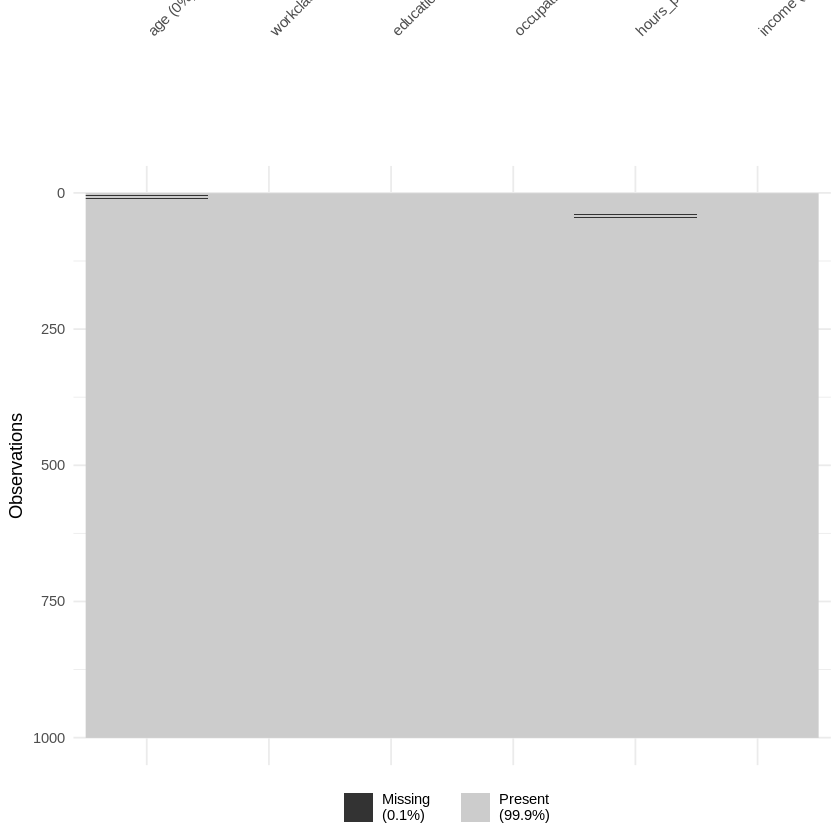

In [81]:
# Visualize missing data

vis_miss(adult_missing)

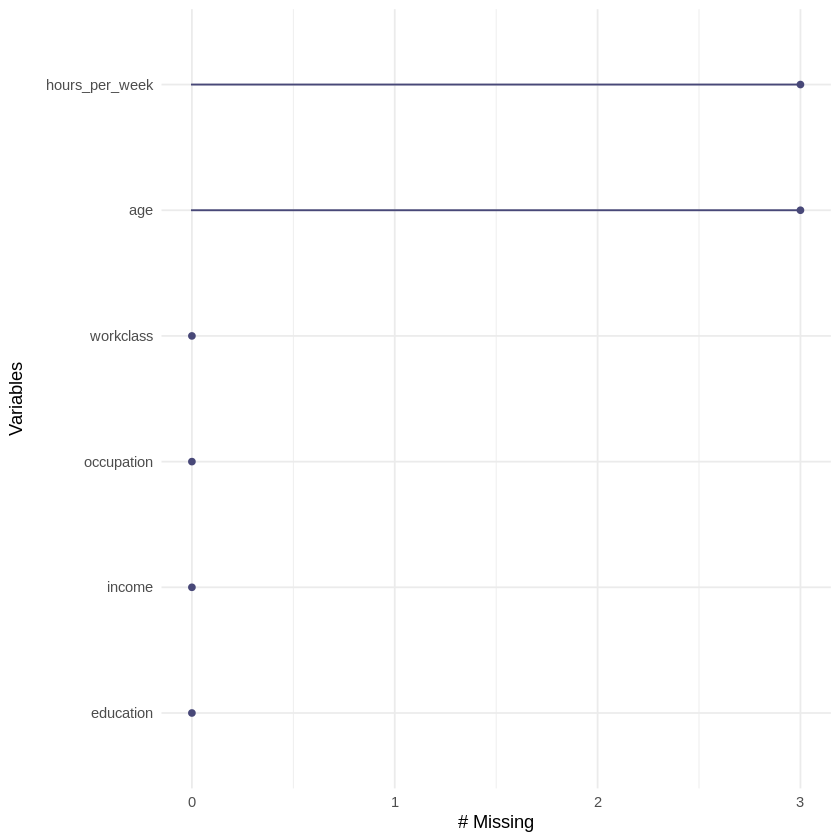

In [82]:
# Visualize missing values by variable

gg_miss_var(adult_missing)

In [83]:
# Comprehensive summary of cleaned dataset

skim(adult_data)

,skim_type,skim_variable,n_missing,complete_rate,character.min,character.max,character.empty,character.n_unique,character.whitespace,numeric.mean,numeric.sd,numeric.p0,numeric.p25,numeric.p50,numeric.p75,numeric.p100,numeric.hist
,<chr>,<chr>,<int>,<dbl>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,character,workclass,0,1,7,13,0,5,0,NA,NA,NA,NA,NA,NA,NA,NA
2,character,education,0,1,3,8,0,4,0,NA,NA,NA,NA,NA,NA,NA,NA
3,character,occupation,0,1,5,8,0,5,0,NA,NA,NA,NA,NA,NA,NA,NA
4,character,income,0,1,4,5,0,2,0,NA,NA,NA,NA,NA,NA,NA,NA
5,numeric,age,0,1,NA,NA,NA,NA,NA,43.786,15.04568,18,30,43,57,70,▇▆▇▇▇
6,numeric,hours_per_week,0,1,NA,NA,NA,NA,NA,39.711,11.80724,20,30,40,50,60,▇▇▇▇▇


In [84]:
# Validate age

cat("Minimum age:", min(adult_data$age, na.rm = TRUE), "\n")
cat("Maximum age:", max(adult_data$age, na.rm = TRUE), "\n")
cat("Age 999 values:", sum(adult_data$age == 999, na.rm = TRUE), "\n")
cat("Missing age values:", sum(is.na(adult_data$age)), "\n")

Minimum age: 18 
Maximum age: 70 
Age 999 values: 0 
Missing age values: 0 


In [85]:
# Validate blank workclass values

blank_workclass <- sum(
  adult_data$workclass == "",
  na.rm = TRUE
)

cat("Blank workclass values:", blank_workclass, "\n")

Blank workclass values: 0 


In [86]:
# Check missing values in every column

missing_summary <- sapply(
  adult_data,
  function(x) sum(is.na(x))
)

missing_summary

age      workclass      education     occupation hours_per_week 
             0              0              0              0              0 
        income 
             0

In [87]:
# Check NaN values

nan_summary <- sapply(
  adult_data,
  function(x) {
    if (is.numeric(x)) {
      sum(is.nan(x))
    } else {
      0
    }
  }
)

nan_summary

age      workclass      education     occupation hours_per_week 
             0              0              0              0              0 
        income 
             0

In [88]:
# Final complete-case validation

complete_count <- sum(complete.cases(adult_data))
incomplete_count <- sum(!complete.cases(adult_data))

cat("Complete observations:", complete_count, "\n")
cat("Incomplete observations:", incomplete_count, "\n")

Complete observations: 1000 
Incomplete observations: 0 


In [89]:
# Before and after missing-data comparison

comparison <- data.frame(
  Stage = c("Before Cleaning", "After Cleaning"),

  Missing_Values = c(
    total_missing_before,
    total_missing_after
  ),

  Missing_Percentage = c(
    missing_percentage_before,
    missing_percentage_after
  )
)

comparison

Stage,Missing_Values,Missing_Percentage
<chr>,<int>,<dbl>
Before Cleaning,6,0.1
After Cleaning,0,0.0


In [90]:
# Before and after missing-data comparison

comparison <- data.frame(
  Stage = c("Before Cleaning", "After Cleaning"),

  Missing_Values = c(
    total_missing_before,
    total_missing_after
  ),

  Missing_Percentage = c(
    missing_percentage_before,
    missing_percentage_after
  )
)

comparison

Stage,Missing_Values,Missing_Percentage
<chr>,<int>,<dbl>
Before Cleaning,6,0.1
After Cleaning,0,0.0


In [91]:
# Before and after missing-data comparison

comparison <- data.frame(
  Stage = c("Before Cleaning", "After Cleaning"),

  Missing_Values = c(
    total_missing_before,
    total_missing_after
  ),

  Missing_Percentage = c(
    missing_percentage_before,
    missing_percentage_after
  )
)

comparison

Stage,Missing_Values,Missing_Percentage
<chr>,<int>,<dbl>
Before Cleaning,6,0.1
After Cleaning,0,0.0


In [92]:
# Export cleaned Adult dataset

write.csv(
  adult_data,
  "cleaned_adult_data.csv",
  row.names = FALSE
)

After executing the above code, the text content of your PDF assignment will be printed. You can then analyze this text to understand the problems and requirements for your R programming tasks. If you want to view the entire content, you can adjust `substr` or print `pdf_content` directly.